## Exploratory Data Analysis (EDA) of our Processed Data

This is to be run after processing the raw data in `notebooks/01_data_cleaning.ipynb`.<br>
For every chart created, we save the output as a .PNG to `visualizations/charts/`. The chart functions live in `analysis/visualize.py`.

### Modules to Import (from `analysis/`)

In [69]:
import sys
sys.path.append("..")

from analysis import data_processing as dp
from analysis import visualize as viz

In [73]:
parcels_tod = dp.load_processed()

In [74]:
dp.inspect(parcels_tod, "Parcels + TOD Zones")

Inspecting Parcels + TOD Zones dataset ...
(43130, 19)
Index(['APN', 'SitusCity', 'Land', 'Imps', 'LatestDocu', 'UseCode', 'geometry',
       'acres', 'zone_id', 'zone_label', 'du_per_acre', 'max_units',
       'epc_class', 'is_epc', 'il_ratio', 'soft_site', 'soft_units',
       'recent_activity', 'tier'],
      dtype='object')


,APN,SitusCity,Land,Imps,LatestDocu,UseCode,geometry,acres,zone_id,zone_label,du_per_acre,max_units,epc_class,is_epc,il_ratio,soft_site,soft_units,recent_activity,tier
4,1-121-12,OAKLAND,348168,812392,2018.0,8100,"POLYGON ((-200475.892 -21660.385, -200468.822 ...",0.086101,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,8,Not EPC,False,2.333333,False,0,True,Tier 1


### Chart 1: Allowed Units by Zone

From this plot we can see that most SB 79 capacity is far from the station, instead of right next to it.

saved to ../outputs/charts/chart1_units_by_zone.png


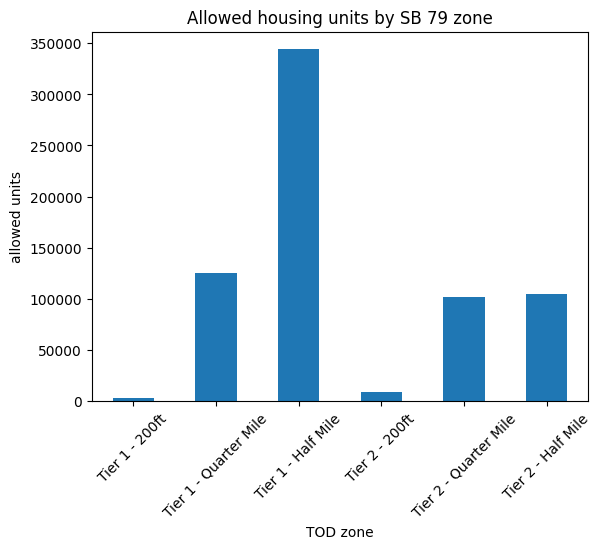

In [75]:
viz.plot_units_by_zone(parcels_tod);

### Charts 2-3: Allowed Units by Zone and EPC Level

**Our main takeaway:** as EPC level rises, SB 79 capacity shifts from Tier 1 (BART) to Tier 2 (Bus Rapid Transit).

saved to ../outputs/charts/chart2_heatmap_total.png


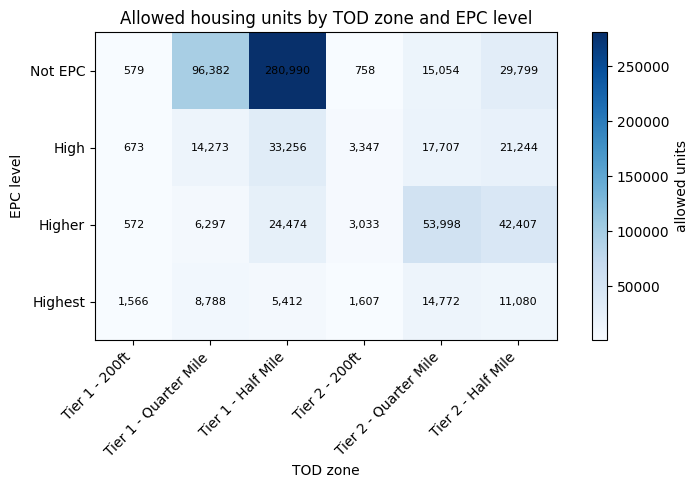

In [76]:
grid = viz.units_by_zone_and_epc(parcels_tod)
viz.plot_heatmap(grid, title="Allowed housing units by TOD zone and EPC level",
                 cbar_label="allowed units", name="chart2_heatmap_total");

saved to ../outputs/charts/chart3_heatmap_share.png


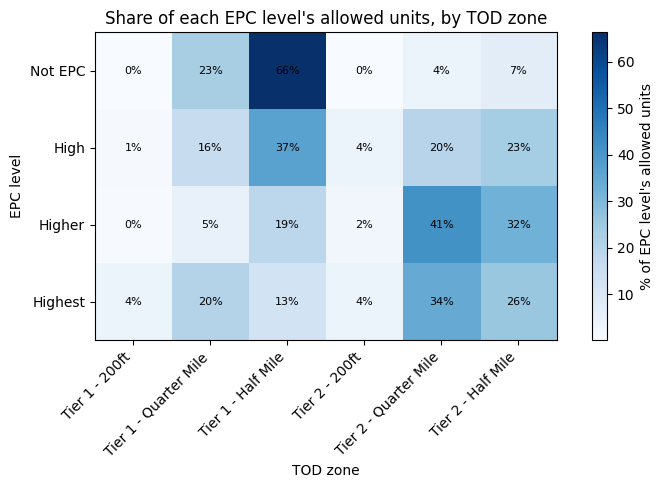

In [77]:
share = viz.row_share(grid)
viz.plot_heatmap(share, title="Share of each EPC level's allowed units, by TOD zone",
                 cbar_label="% of EPC level's allowed units", name="chart3_heatmap_share", fmt="{:.0f}%");

In [78]:
viz.tier_share_by_epc(parcels_tod).style.format("{:.0f}%")

tier,Tier 1,Tier 2
epc_class,,
Not EPC,89%,11%
High,53%,47%
Higher,24%,76%
Highest,36%,64%


**To re-iterate:** we observe that as EPC level rises, SB 79 capacity shifts from Tier 1 (BART) to Tier 2 (Bus Rapid Transit).

### Chart 4: Allowed vs. Soft-Site Units

Reminder: a "soft site" is a parcel where the building is worth **less than half the land**.<br>It looks like only a small "slice" of allowed capacity sits on soft sites, and that slice gets *smaller* as EPC level rises.

saved to ../outputs/charts/chart4_allowed_vs_soft.png


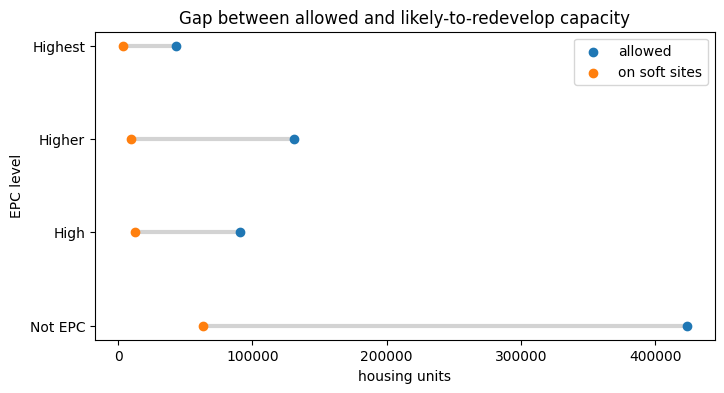

In [79]:
viz.plot_allowed_vs_soft(parcels_tod);